# REACT tutorial: evaluate your own forecaster

REACT follows a probabilistic trajectory forecast through each detected change in a person's motion (a stop, a start, a turn) and reports four things per event:

- **anticipation**: the forecast never fell behind a climatological reference;
- **REACT**: frames until it was confidently ahead again;
- **censoring**: it never got there within the window;
- **relapse**: it got there, then fell behind again within 10 frames.

Every number is written $\mathrm{REACT}(h, d;\ I)$: lead $h$ in frames, an optional target distance $d$ in metres, and an assumed information level $I$ in nats. This notebook takes a forecaster you write yourself through the whole workflow on real pedestrian data, and shows how to read the result.

It needs `pip install "reactmetric[viz,datasets]"` and about 10 minutes on a laptop.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import reactmetric as rm

print(rm.__version__)

0.2.0.dev0


## 1. Data

Eindhoven Centraal train-platform trajectories (Pouw et al., Zenodo 10.5281/zenodo.13784588, CC-BY-4.0), at 10 Hz in metres. The first call downloads one ten-day shard (about 860 MB) to `~/.cache/reactmetric`; `max_tracks` keeps this tutorial quick. With no download, `rm.datasets.load_eindhoven_sample()` gives a bundled 36-track sample, which is enough to run the code but too small for conclusions.

REACT needs **long, continuous tracks** (events need at least 25 frames before the next one) and a forecast at **every frame**, not one per scenario.

In [2]:
data = rm.datasets.load_eindhoven(download=True, max_tracks=600)
lengths = np.array([data[t].T for t in data.ids])
print(f"{len(data)} tracks, dt = {data.dt:.2f} s, median length {np.median(lengths) / 10:.0f} s, "
      f"{lengths.sum() / 10 / 3600:.1f} hours")

calib, test = data.split(fraction=0.3, seed=0)   # calibration fits REACT itself; never test on it
print(f"{len(calib)} calibration / {len(test)} test tracks")

556 tracks, dt = 0.10 s, median length 14 s, 4.1 hours
167 calibration / 389 test tracks


## 2. Your forecaster

A forecaster is anything with `predict(traj) -> rm.Predictive`. A `Predictive` holds, for each **issue frame** $t$, Gaussian forecasts of the position at frames $t+1, \dots, t+H$:

- `issue_frames` (n,): the **last observed frame**. The forecast may use observations up to and including it, never after.
- `means` (n, H, 2) and `covs` (n, H, 2, 2): column $h-1$ is lead $h$, which targets frame issue $+\ h$.

Here is a deliberately simple model: extrapolate the velocity of the last half second, with an isotropic spread that grows with lead.

In [3]:
class LinearExtrapolation:
    """Velocity from the last `history` frames; spread sigma0 + growth * (lead in seconds)."""

    def __init__(self, history=5, horizon=15, sigma0=0.03, growth=0.25):
        self.history, self.horizon, self.sigma0, self.growth = history, horizon, sigma0, growth

    def predict(self, traj):
        pos, dt, H = traj.positions, traj.dt, self.horizon
        issue = np.arange(self.history, len(pos) - 1)            # last observed frames
        if len(issue) == 0:
            return None
        v = (pos[issue] - pos[issue - self.history]) / (self.history * dt)
        leads = np.arange(1, H + 1) * dt                          # seconds ahead
        means = pos[issue][:, None, :] + leads[None, :, None] * v[:, None, :]
        sd = self.sigma0 + self.growth * leads
        covs = (sd**2)[None, :, None, None] * np.eye(2)
        return rm.Predictive(issue, means, np.broadcast_to(covs, (len(issue), H, 2, 2)).copy())


mine = LinearExtrapolation()
p = mine.predict(test[test.ids[0]])
target, mu, S = p.at_lead(10)
print(f"{len(p)} issue frames; lead 10 of the first forecast targets frame {target[0]} "
      f"(issued at {p.issue_frames[0]})")

338 issue frames; lead 10 of the first forecast targets frame 15 (issued at 5)


**Parallel runs and notebooks.** `evaluate(..., n_jobs=8)` scores tracks in worker processes. Classes defined in a notebook cannot be sent to those workers, so either keep `n_jobs=1` for notebook-defined models, or do what this tutorial does: compute the forecasts once into a dict `{track id: Predictive}`, which works with any `n_jobs`. In a script, put the run under `if __name__ == "__main__":`.

In [4]:
my_forecasts = {t: mine.predict(test[t]) for t in test.ids}
my_calib_forecasts = {t: mine.predict(calib[t]) for t in calib.ids}

## 3. Fit REACT on the calibration tracks

`ReactScorer.fit` fits everything REACT shares across models:

- the **climatology**: where a person is likely to be $h$ frames ahead given only their last step;
- the **measurement-noise floor** $\sigma$, from stationary frames;
- the **truth model's** correlation structure at each lead and information level;
- lookup tables for the exact tests.

Passing models here also reports their **demonstrated information**: the mean realized gain over climatology on calm stretches. It is a lower bound on how much information the trajectories carry.

The paper reports 3, 4.2 and 6 nats with 4.2 as the headline. Leads 5 and 10 keep this quick (the paper also uses 1 and 15).

In [5]:
cv = rm.baselines.ConstantVelocity.fit(calib)        # maximum-likelihood noise on calibration
scorer = rm.ReactScorer.fit(
    calib, info=(3.0, 4.2, 6.0), leads=(5, 10), distortions=(0.1, 0.3),
    forecasts={"Mine": my_calib_forecasts, "CV": cv}, n_jobs=os.cpu_count(),
)
print("noise floor:", f"{scorer.noise_floor['sigma_cm']:.2f} cm")
for lead in scorer.leads:
    print(f"lead {lead}: demonstrated information (nats/frame)",
          {m: round(v, 2) for m, v in scorer.calibration[lead]["calm_mean_score"].items()})

noise floor: 1.40 cm
lead 5: demonstrated information (nats/frame) {'Mine': 0.11, 'CV': 0.15}
lead 10: demonstrated information (nats/frame) {'Mine': 0.22, 'CV': 0.05}


## 4. Evaluate against baselines

Constant velocity (fitted above), CTRV and IMM (default noise), and **Oracle B**, which is always included: the best forecast the assumptions allow, so its REACT is the floor.

In [6]:
models = {"Mine": my_forecasts, "CV": cv, "CTRV": rm.baselines.CTRV(), "IMM": rm.baselines.IMM()}
result = scorer.evaluate(models, test, n_jobs=os.cpu_count())
events = {(r["track"], r["t0"]) for r in result.records}
print(f"{len(events)} events, {len(result.records):,} records")

659 events, 56,853 records


## 5. Read the profile

One row per model at $\mathrm{REACT}(10, \infty;\ 4.2)$:

- `anticipation`: share of events with no onset.
- `km_react`: median REACT in frames, given onset (Kaplan–Meier).
- `censored`: share of all events that fell behind and never recovered in the window.
- `relapse3`: share of recoveries that fell behind again.
- `rmst`: restricted mean frames to recovery over all events, with anticipated events at 0.
- `mean_s_mixture`: mean realized log-score gain over climatology in the event windows (nats/frame).

In [7]:
cols = ["model", "events", "anticipation", "km_react", "censored", "relapse3", "rmst",
        "mean_s_mixture"]
result.table(lead=10, info=4.2, distortion=0.0)[cols].round(2)

,model,events,anticipation,km_react,censored,relapse3,rmst,mean_s_mixture
0,oracle_B,659,0.00,1.0,0.00,0.00,1.02,4.26
1,Mine,659,0.19,11.0,0.04,0.28,15.00,0.05
2,CV,637,0.17,9.0,0.05,0.25,15.26,-0.06
3,CTRV,637,0.12,15.0,0.05,0.52,20.79,-0.90
4,IMM,637,0.13,10.0,0.03,0.51,14.70,0.12


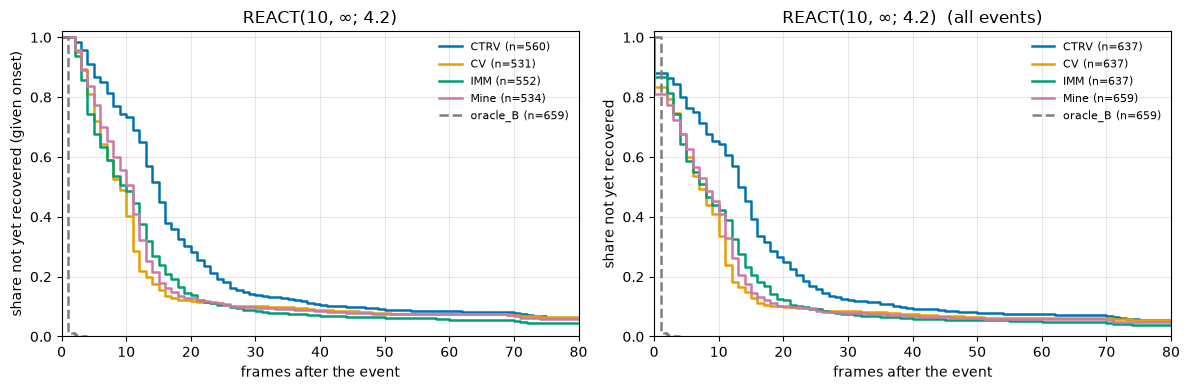

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rm.viz.km_curves(result, lead=10, info=4.2, given_onset=True, max_frames=80, ax=axes[0])
rm.viz.km_curves(result, lead=10, info=4.2, given_onset=False, max_frames=80, ax=axes[1])
axes[1].set_title(axes[1].get_title() + "  (all events)")
plt.show()

Read the left panel as: of the events where a model fell behind, what share has not yet recovered $\tau$ frames later. A curve that drops early recovers quickly; a curve that flattens high leaves events unrecovered. The right panel counts anticipated events as recovered at frame 0.

## 6. Choose the target and the information level

**Target distance $d$.** Beating climatology is a relative advantage. With $d = 0.1$ m, recovery also requires the forecast to be sharp enough to localize the person within 10 cm RMS. Oracle B's censoring shows whether a target is reachable at all.

In [9]:
result.table(lead=10, info=4.2, distortion=0.1)[cols].round(2)

,model,events,anticipation,km_react,censored,relapse3,rmst,mean_s_mixture
0,oracle_B,659,0.00,2.0,0.01,0.00,5.22,4.26
1,Mine,659,0.19,48.0,0.34,0.20,57.46,0.05
2,CV,637,0.17,57.0,0.39,0.20,64.30,-0.06
3,CTRV,637,0.12,45.0,0.34,0.46,58.45,-0.90
4,IMM,637,0.13,44.0,0.31,0.40,56.40,0.12


**Information level $I$.** An assumption about how much of the next position is knowable beyond climatology. Raising it makes each frame more decisive and shortens REACT. Report results with their level, and check that model orderings hold across levels.

In [10]:
rows = []
for info in (3.0, 4.2, 6.0):
    tb = result.table(lead=10, info=info, distortion=0.0)
    rows.append(tb.set_index("model")["km_react"].rename(f"I = {info}"))
pd.concat(rows, axis=1)

,I = 3.0,I = 4.2,I = 6.0
model,,,
oracle_B,1.0,1.0,1.0
Mine,12.0,11.0,9.0
CV,10.0,9.0,8.0
CTRV,16.0,15.0,13.0
IMM,13.0,10.0,8.0


In [11]:
level, shares = result.info_level(distortion=0.1)   # the paper's rule: lowest level where
print("headline level:", level)                       # Oracle B recovers on >= 95% at every lead
pd.DataFrame(shares).round(3)

headline level: 4.2


,3.0,4.2,6.0
5,0.986,0.998,0.998
10,0.939,0.994,1.000


## 7. Drill into events

Every record is one (lead, level, target, model, event). Group them however you like, for example by event type.

In [12]:
df = result.to_dataframe()
sel = df[(df.lead == 10) & (df["info"] == 4.2) & (df.distortion == 0.0) & (df.model != "oracle_B")]
onset = sel[sel.status.isin(["recovered", "censored"])]
(onset.assign(censored=onset.status.eq("censored"))
      .groupby(["event_type", "model"])["censored"].mean().unstack().round(2))

model,CTRV,CV,IMM,Mine
event_type,,,,
both,0.03,0.00,0.00,0.00
speed_change,0.04,0.04,0.03,0.03
start,0.00,0.00,0.00,0.00
stop,0.34,0.31,0.22,0.32
turn,0.00,0.00,0.00,0.00
turn_change,0.00,0.20,0.00,0.17


## 8. A multimodal version of your model

If your model can say "keeps walking, or stops", give it as a mixture. REACT scores the mixture itself, so a correct second mode is rewarded rather than blurred into one wide Gaussian.

In [13]:
class StopOrGo(LinearExtrapolation):
    """70%: keep going (the linear model); 30%: stop where you are."""

    def predict(self, traj):
        p = super().predict(traj)
        if p is None:
            return None
        n, H = p.means.shape[:2]
        stay = np.repeat(traj.positions[p.issue_frames][:, None, :], H, axis=1)
        means = np.stack([p.means, stay], axis=2)                          # (n, H, 2 modes, 2)
        covs = np.stack([p.covs, np.broadcast_to(0.05**2 * np.eye(2), p.covs.shape)], axis=2)
        return rm.MixturePredictive(p.issue_frames, np.tile([0.7, 0.3], (n, 1)), means, covs)


both = scorer.evaluate({"Mine": my_forecasts,
                        "StopOrGo": {t: StopOrGo().predict(test[t]) for t in test.ids}},
                       test, n_jobs=os.cpu_count())
both.table(lead=10, info=4.2, distortion=0.0)[cols].round(2)

,model,events,anticipation,km_react,censored,relapse3,rmst,mean_s_mixture
0,oracle_B,659,0.00,1.0,0.00,0.00,1.02,4.26
1,Mine,659,0.19,11.0,0.04,0.28,15.00,0.05
2,StopOrGo,659,0.10,8.0,0.02,0.39,12.19,0.20


## 9. Save, with the assumptions

`to_json` writes the summary together with the settings every number depends on (leads, levels, targets, decision probability, noise floor, windows). `to_csv` writes the per-event records.

In [14]:
os.makedirs("react_tutorial", exist_ok=True)
result.to_json("react_tutorial/summary.json")
result.to_csv("react_tutorial/records.csv")
result.settings()

{'leads': [5, 10],
 'info_levels': {'5': [3.0, 4.2, 6.0], '10': [3.0, 4.2, 6.0]},
 'distortions_m': [None, 0.1, 0.3],
 'decision_probability': 0.95,
 'noise_floor': {'floor': 'A',
  'sigma_cm': 1.4001904078542449,
  'residuals_per_axis': 9063,
  'tracks': 22},
 'onset_window': 'lead + 5 frames',
 'window_cap_frames': 150,
 'min_window_frames': 25}

## Notes

- Settings are counted in frames at 10 Hz, as in the paper. Resample other frame rates to 10 Hz first.
- REACT is a profile, not a leaderboard number: anticipation, recovery time, completeness and relapse can favour different models.
- Method and defaults: the paper (Breseman and Woollard, *REACT: Measuring Regime Adaptation in Trajectories*, TGF 2026) and `docs/concepts.md`.